In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/datasets/sagarikashreevastava/cognitive-distortion-detetction-dataset/Therapist_responses.csv
/kaggle/input/datasets/sagarikashreevastava/cognitive-distortion-detetction-dataset/Annotated_data.csv
/kaggle/input/datasets/sagarikashreevastava/cognitive-distortion-detetction-dataset/README.md
/kaggle/input/datasets/arafahmed98/df-masterno-aug/df_master.csv


In [ ]:
import torch
import transformers
from transformers.modeling_utils import ModuleUtilsMixin, PreTrainedModel

# ==============================================================
# SOFT MONKEY PATCH FOR 2x T4 GPU 
# Bypasses StopIteration but allows AMP to work perfectly
# ==============================================================
def _forced_dtype_safe(self):
    return torch.float32

# Overwrite the property
ModuleUtilsMixin.dtype = property(_forced_dtype_safe)
PreTrainedModel.dtype = property(_forced_dtype_safe)

print("Safe Patch applied! Ready for Multi-GPU AMP.")

In [ ]:
df_short_synthetic = pd.read_csv("/kaggle/input/datasets/arafahmed98229/synthetic-cognitive-distortion-dataset-scdd-2-2k/Final_CBT_Dataset.csv")
df_long_synthetic = pd.read_csv("/kaggle/input/datasets/arafahmed98229/cbt-longcontext-synthetic-datset/synthetic_aligned_labels.csv")
df_real = pd.read_csv("/kaggle/input/datasets/sagarikashreevastava/cognitive-distortion-detetction-dataset/Annotated_data.csv")
df_taf_synthetic = pd.read_csv("/kaggle/input/datasets/arafahmed98229/taf-synthetic/modernbert_taf_cleaned_dataset.csv")

dropping JTC from short synthetic as its a parent label we will add fortune telling and mind reading who are its subtypes to match the real  dataset and work with a detailed distortions.

In [ ]:
df_short_synthetic.columns
df_short_synthetic.shape

In [ ]:
print(df_short_synthetic['dominant_distortion'].value_counts())
print(df_short_synthetic['secondary_distortion'].value_counts())

In [ ]:
df_short_synthetic = df_short_synthetic[df_short_synthetic['dominant_distortion'] != 'Jumping to Conclusions']
df_short_synthetic = df_short_synthetic[df_short_synthetic['secondary_distortion'] != 'Jumping to Conclusions']

verifying the drop

In [ ]:
print(df_short_synthetic['dominant_distortion'].value_counts())
print(df_short_synthetic['secondary_distortion'].value_counts())

data merging and cleaning the extra data generated for fortune telling and mind reading, to replace the JTC from the SCDD2.2k

In [ ]:
import pandas as pd
files_to_merge = [
    "/kaggle/input/datasets/arafahmed98229/mindreading-and-fortunetelling-data-synthetic/mindReading_1.csv",
    "/kaggle/input/datasets/arafahmed98229/mindreading-and-fortunetelling-data-synthetic/mindReading_2.csv",
    "/kaggle/input/datasets/arafahmed98229/mindreading-and-fortunetelling-data-synthetic/mindReading_3.csv",
    "/kaggle/input/datasets/arafahmed98229/mindreading-and-fortunetelling-data-synthetic/mindReading_4.csv",
    "/kaggle/input/datasets/arafahmed98229/mindreading-and-fortunetelling-data-synthetic/mindReading_5.csv",
    "/kaggle/input/datasets/arafahmed98229/mindreading-and-fortunetelling-data-synthetic/fortuneTelling_1.csv",
    "/kaggle/input/datasets/arafahmed98229/mindreading-and-fortunetelling-data-synthetic/fortuneTelling_2.csv",
    "/kaggle/input/datasets/arafahmed98229/mindreading-and-fortunetelling-data-synthetic/fortuneTelling_3.csv",
    "/kaggle/input/datasets/arafahmed98229/mindreading-and-fortunetelling-data-synthetic/fortuneTelling_4.csv",
    "/kaggle/input/datasets/arafahmed98229/mindreading-and-fortunetelling-data-synthetic/fortuneTelling_5.csv"
    
]

df_mr_ft_combined = pd.concat([pd.read_csv(f) for f in files_to_merge], ignore_index=True)
df_mr_ft_combined.columns = df_mr_ft_combined.columns.str.lower().str.replace(' ', '_')
df_mr_ft_combined.to_csv('mr_ft_combined_synthetic.csv', index=False)
print(f"Merge successful! Total rows: {len(df_mr_ft_combined)}")

In [ ]:
for p in files_to_merge:
    temp_df = pd.read_csv(p)
    print(f"File: {p.split('/')[-1]} | Rows: {len(temp_df)}")

In [ ]:
print(df_mr_ft_combined.shape)
print(df_mr_ft_combined['dominant_distortion'].value_counts())
print(df_mr_ft_combined['secondary_distortion'].value_counts())
df_mr_ft_combined.isnull().value_counts()

now merging the fortune telling and mind reading data with short synthetic

In [ ]:
df_short_synthetic_stage_1 = pd.concat([df_mr_ft_combined, df_short_synthetic], ignore_index=True)

In [ ]:
print(df_short_synthetic_stage_1.columns)

In [ ]:
print(df_short_synthetic_stage_1['dominant_distortion'].value_counts())
print(df_short_synthetic_stage_1['secondary_distortion'].value_counts())

merging minimization and magnification as they are same and act as two sides of a coin

In [ ]:

final_harmonize = {
    'Minimization': 'Magnification or Minimization',
    'Magnification': 'Magnification or Minimization'
}

df_short_synthetic_stage_1['dominant_distortion'] = df_short_synthetic_stage_1['dominant_distortion'].replace(final_harmonize)
df_short_synthetic_stage_1['secondary_distortion'] = df_short_synthetic_stage_1['secondary_distortion'].replace(final_harmonize)

print(df_short_synthetic_stage_1['dominant_distortion'].value_counts())
print(df_short_synthetic_stage_1['secondary_distortion'].value_counts())
print(df_short_synthetic_stage_1.shape)

as of the data for short synthetic is clean, now lets clean the long synthetic data

In [ ]:
df_long_synthetic.columns

dropping extra id column in long synthetic

In [ ]:
df_long_synthetic = df_long_synthetic.drop('id', axis=1)

In [ ]:
df_long_synthetic.columns

In [ ]:
print(df_long_synthetic['dominant_distortion'].value_counts())
print(df_long_synthetic['secondary_distortion'].value_counts())
print(df_long_synthetic.shape)

now merg the long and short synthetic and also find if there is any label leckage and fix the label leckage

In [ ]:
# 1. Merge the datasets
df_stage1_master = pd.concat([df_short_synthetic_stage_1, df_long_synthetic], ignore_index=True)

# 2. Final Label Harmonization
master_label_fix = {
    # Fix Casing & Hyphens
    'Fortune-telling': 'Fortune Telling',
    'fortune-telling': 'Fortune Telling',
    'Should statements': 'Should Statements',
    'should statements': 'Should Statements',
    'Mental filter': 'Mental Filter',
    'mental filter': 'Mental Filter',
    'Emotional reasoning': 'Emotional Reasoning',
    'emotional reasoning': 'Emotional Reasoning',
    'All-or-nothing thinking': 'All-or-Nothing Thinking',
    'all-or-nothing thinking': 'All-or-Nothing Thinking',
    'Overgeneralization ': 'Overgeneralization', # Fixes accidental trailing spaces
    
    # Collapse Fragmented Labels if any 
    'Magnification': 'Magnification or Minimization',
    'Minimization': 'Magnification or Minimization',
    'magnification': 'Magnification or Minimization',
    'minimization': 'Magnification or Minimization'
}

df_stage1_master['dominant_distortion'] = df_stage1_master['dominant_distortion'].replace(master_label_fix)
df_stage1_master['secondary_distortion'] = df_stage1_master['secondary_distortion'].replace(master_label_fix)

# 3. The "Leakage" Filter
# Removes rows where the AI accidentally included the label in the text
# Expanded forbidden list to catch missed labels and synonyms
forbidden = [
    'mind reading', 'fortune telling', 'all-or-nothing', 'should statement',
    'minimization', 'magnification', 'overgeneralization', 'emotional reasoning',
    'mental filter', 'disqualifying the positive', 'labeling', 'personalization',
    'jumping to conclusions', 'catastrophizing', 'cognitive distortion'
]

pattern = '|'.join(forbidden)
print(f"Final Stage 1 Master Ready: {df_stage1_master.shape}")
print(f"Final cleaned row count: {len(df_stage1_master)}")
pattern = '|'.join(forbidden)
print(df_stage1_master['dominant_distortion'].value_counts())
print(df_stage1_master['secondary_distortion'].value_counts())
# checking how many got dropped
# Apply the filter
df_stage1_master = df_stage1_master[~df_stage1_master['text'].str.contains(pattern, case=False, na=False)]
print(f"Final Stage 1 Master Ready: {df_stage1_master.shape}")
print(df_stage1_master['dominant_distortion'].value_counts())
print(df_stage1_master['secondary_distortion'].value_counts())

label polish now

In [ ]:
# 1. Final check for any 'invisible' duplicates (e.g., "Labeling" vs "Labeling ")
df_stage1_master['dominant_distortion'] = df_stage1_master['dominant_distortion'].str.strip()
df_stage1_master['secondary_distortion'] = df_stage1_master['secondary_distortion'].str.strip()

# 2. Convert to Title Case for total consistency
df_stage1_master['dominant_distortion'] = df_stage1_master['dominant_distortion'].str.title()
df_stage1_master['secondary_distortion'] = df_stage1_master['secondary_distortion'].str.title()

# 3. Quick re-fix for 'All-Or-Nothing' (Title case makes 'or' into 'Or')
df_stage1_master['dominant_distortion'] = df_stage1_master['dominant_distortion'].replace({'All-Or-Nothing Thinking': 'All-or-Nothing Thinking'})
df_stage1_master['secondary_distortion'] = df_stage1_master['secondary_distortion'].replace({'All-Or-Nothing Thinking': 'All-or-Nothing Thinking'})

print(f"Final Class Count: {df_stage1_master['dominant_distortion'].nunique()}")
print(f"Final Class Count: {df_stage1_master['secondary_distortion'].nunique()}")

saving the stage one dataset

In [ ]:
df_stage1_master.to_csv('stage1_foundation_final_synthetics.csv', index=False)

working starts from here, re train the pretrain

In [1]:
import pandas as pd
pre_df = pd.read_csv("/kaggle/input/datasets/arafahmed98/df-masterno-aug/df_master.csv")
print(pre_df['source'].value_counts())
print(pre_df.shape)
print(pre_df['dominant_distortion'].value_counts())
# Drop rows with source == "real"
_df = pre_df[pre_df['source'] != 'real'].copy()
df = _df[_df['source'] != 'synthetic_taf'].copy()


print(df['source'].value_counts())
print(df.shape)
print(df['dominant_distortion'].value_counts())
import os

os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

source
synthetic_cbt    3153
real             2508
synthetic_taf     949
Name: count, dtype: int64
(6610, 4)
dominant_distortion
No Distortion                 1428
Mind Reading                   524
Overgeneralization             521
Magnification                  499
Should Statements              450
Labeling                       444
Personalization                426
Emotional Reasoning            424
Mental Filter                  407
All-or-Nothing Thinking        402
Fortune Telling                379
Disqualifying the Positive     246
TAF-Shape                      179
TAF-Likelihood                 178
TAF-Morality                   103
Name: count, dtype: int64
source
synthetic_cbt    3153
Name: count, dtype: int64
(3153, 4)
dominant_distortion
No Distortion                 340
Should Statements             307
All-or-Nothing Thinking       282
Emotional Reasoning           269
Mental Filter                 266
Magnification                 265
Mind Reading                  2

as this is synthetic stage one 1 training, drop the real rows  and taf as planned

In [2]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
from transformers import (
    AutoConfig, 
    AutoTokenizer, 
    AutoModelForSequenceClassification, 
    TrainingArguments, 
    Trainer,DataCollatorWithPadding
)
from datasets import Dataset
from sklearn.metrics import f1_score, classification_report

now lets train the stage one mentalRobertalarge

using the dataset what was exported

label mapping

multi hot vectorization

In [3]:
import pandas as pd
import numpy as np


# --- STEP 2: Establish the Master Label Mapping ---
# Sorting ensures the index [0] is always 'All-or-Nothing Thinking', etc.
label_names = sorted([
    'All-or-Nothing Thinking', 'Disqualifying the Positive', 'Emotional Reasoning',
    'Fortune Telling', 'Labeling', 'Magnification', 
    'Mental Filter', 'Mind Reading', 'Overgeneralization', 'Personalization', 
    'Should Statements'
])

label2id = {l: i for i, l in enumerate(label_names)}
id2label = {i: l for l, i in label2id.items()}
num_labels = len(label_names)

# Create a lowercase map to ensure 100% match accuracy during encoding
clean_map = {name.lower().strip(): i for i, name in enumerate(label_names)}

# --- STEP 3: The Multi-Hot Encoding Function ---
def create_multihot(row):
    # Initialize a vector of 11 zeros
    vector = np.zeros(num_labels, dtype=np.float32)
    
    # Grab strings from the columns and normalize for matching
    dom = str(row['dominant_distortion']).lower().strip()
    sec = str(row['secondary_distortion']).lower().strip()
    
    # Flip the bit to 1.0 if the distortion is found in our map
    if dom in clean_map:
        vector[clean_map[dom]] = 1.0
        
    # Flip the bit for secondary distortion (if it's not a duplicate)
    if sec in clean_map and sec != dom:
        vector[clean_map[sec]] = 1.0
        
    return list(vector)

# --- STEP 4: Apply Encoding and Verify ---
print("Encoding labels into binary vectors...")
df['labels'] = df.apply(create_multihot, axis=1)

# Verification logic to ensure no class has 0.0 support
final_matrix = np.stack(df['labels'].values)
final_counts = final_matrix.sum(axis=0)

print("\n--- FINAL VERIFIED BINARY MATRIX COUNTS ---")
for name, count in zip(label_names, final_counts):
    print(f"{name:.<35} {count:>5}")

print("\n Data is now binary-ready. Proceed to Stratified Split!")

Encoding labels into binary vectors...

--- FINAL VERIFIED BINARY MATRIX COUNTS ---
All-or-Nothing Thinking............ 464.0
Disqualifying the Positive......... 305.0
Emotional Reasoning................ 437.0
Fortune Telling.................... 338.0
Labeling........................... 464.0
Magnification...................... 448.0
Mental Filter...................... 448.0
Mind Reading....................... 400.0
Overgeneralization................. 441.0
Personalization.................... 424.0
Should Statements.................. 489.0

 Data is now binary-ready. Proceed to Stratified Split!


In [4]:
# 1. Install the correct, modern library
!pip install -q iterative-stratification

import numpy as np
import pandas as pd
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

# 2. Extract ONLY the labels into a 2D matrix for the stratifier to do its math
# (We leave the text safely inside the dataframe)
y_matrix = np.stack(df['labels'].values)

print("Starting 70/30 Train/Temp Split...")
# 3. First Split: 70% Train, 30% Temp
msss_1 = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=0.3, random_state=42)

for train_index, temp_index in msss_1.split(df['text'], y_matrix):
    train_df = df.iloc[train_index].reset_index(drop=True)
    temp_df  = df.iloc[temp_index].reset_index(drop=True)
    y_temp_matrix = y_matrix[temp_index] # Keep the matrix for the second split

print("Starting 50/50 Val/Test Split...")
# 4. Second Split: Cut the 30% Temp exactly in half (15% Val, 15% Test)
msss_2 = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=0.5, random_state=42)

for val_index, test_index in msss_2.split(temp_df['text'], y_temp_matrix):
    val_df  = temp_df.iloc[val_index].reset_index(drop=True)
    test_df = temp_df.iloc[test_index].reset_index(drop=True)

print("\n" + "="*50)
print(f"SPLIT SUCCESSFUL!")
print(f"Train: {len(train_df)} rows")
print(f"Val:   {len(val_df)} rows")
print(f"Test:  {len(test_df)} rows")
print("="*50)

Starting 70/30 Train/Temp Split...
Starting 50/50 Val/Test Split...

SPLIT SUCCESSFUL!
Train: 2207 rows
Val:   473 rows
Test:  473 rows


In [2]:
!pip install -q huggingface_hub

from huggingface_hub import login

login("") #use your own HF sceret

In [7]:
import torch
import torch.nn as nn
import numpy as np
from transformers import (
    AutoConfig,
    AutoModelForSequenceClassification,
    AutoTokenizer,
    Trainer,
    TrainingArguments,
    DataCollatorWithPadding
)
from transformers.trainer_callback import EarlyStoppingCallback
from sklearn.metrics import f1_score

# ==========================================
# 1. INITIALIZE MODERNBERT (11 CBT CLASSES)
# ==========================================
model_name = "AIMH/mental-roberta-large"
tokenizer = AutoTokenizer.from_pretrained(model_name)
num_labels = 11  # Matches your 11 sorted CBT distortions

config = AutoConfig.from_pretrained(model_name)
config.num_labels = num_labels
config.problem_type = "multi_label_classification"

model = AutoModelForSequenceClassification.from_pretrained(
    model_name, 
    config=config
)
model.eval()

# ==========================================
# 2. HUGGING FACE PYTORCH DATASET SETUP
# ==========================================
#512 for roberta varients
class CBTDataset(torch.utils.data.Dataset):
    def __init__(self, df, tokenizer, max_len=512):
        self.texts = df['text'].values
        self.labels = np.stack(df['labels'].values).astype(np.float32)
        self.tokenizer = tokenizer
        self.max_len = max_len
        
    def __len__(self):
        return len(self.texts)
        
    def __getitem__(self, idx):
        encoding = self.tokenizer(
            str(self.texts[idx]), 
            max_length=self.max_len, 
            truncation=True
        )
        return {
            'input_ids': encoding['input_ids'],
            'attention_mask': encoding['attention_mask'],
            'labels': self.labels[idx].tolist()  # Converted to list for data collator
        }

# Build dataset wrappers from your stratified splits
train_ds = CBTDataset(train_df, tokenizer)
val_ds = CBTDataset(val_df, tokenizer)
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

# ==========================================
# 3. ASYMMETRIC LOSS FUNCTION (RAW MODE)
# ==========================================
class AsymmetricLossRaw(nn.Module):
    def __init__(self, gamma_neg=1, gamma_pos=1, eps=1e-8):
        super().__init__()
        self.gamma_neg = gamma_neg
        self.gamma_pos = gamma_pos
        self.eps = eps

    def forward(self, logits, targets, pos_weights):
        xs_pos = torch.sigmoid(logits)
        xs_neg = 1 - xs_pos

        los_pos = targets * torch.log(xs_pos.clamp(min=self.eps))
        los_neg = (1 - targets) * torch.log(xs_neg.clamp(min=self.eps))

        loss = -(los_pos * (1 - xs_pos)**self.gamma_pos * pos_weights + 
                 los_neg * (1 - xs_neg)**self.gamma_neg)
        return loss.mean()

class ASLTrainer(Trainer):
    def __init__(self, pos_weights, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.pos_weights = pos_weights
        self.asl_loss = AsymmetricLossRaw(gamma_neg=1, gamma_pos=1)

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        loss = self.asl_loss(outputs.get("logits"), labels, self.pos_weights.to(labels.device))
        return (loss, outputs) if return_outputs else loss

# ==========================================
# 4. COMPUTE IMBALANCE POSITIONAL WEIGHTS
# ==========================================
train_labels_matrix = np.stack(train_df['labels'].values)
pos_weights = torch.zeros(num_labels)
for i in range(num_labels):
    pos = (train_labels_matrix[:, i] == 1).sum()
    neg = (train_labels_matrix[:, i] == 0).sum()
    pos_weights[i] = np.sqrt(neg / pos) if pos > 0 else 1.0

# ==========================================
# 5. STANDARD CLASSIFICATION METRICS
# ==========================================
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    probs = 1 / (1 + np.exp(-logits))
    preds = (probs >= 0.5).astype(int)
    return {
        "macro_f1": f1_score(labels, preds, average="macro", zero_division=0),
        "micro_f1": f1_score(labels, preds, average="micro", zero_division=0)
    }

# ==========================================
# 6. TRAINING ARGUMENTS (V5-CLEANED)
# ==========================================
args = TrainingArguments(
    output_dir="./modernbert_cbt_asl",
    learning_rate=2e-5,
    per_device_train_batch_size=1,
    per_device_eval_batch_size=1,
    gradient_accumulation_steps=16,
    num_train_epochs=6,
    group_by_length=True,
    eval_strategy="epoch",  
    save_strategy="epoch",
    logging_steps=25,
    save_total_limit=2,
    
    fp16=torch.cuda.is_available(),
    report_to="none",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    
    dataloader_num_workers=0,
    ddp_find_unused_parameters=False,
    local_rank=-1
)

# ==========================================
# 7. EXECUTION
# ==========================================
trainer = ASLTrainer(
    pos_weights=pos_weights.to("cuda" if torch.cuda.is_available() else "cpu"),
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)]
)

# Clear VRAM cache allocations before starting
torch.cuda.empty_cache()

trainer.train()

Epoch,Training Loss,Validation Loss,Macro F1,Micro F1
1,3.906064,0.179296,0.715992,0.701782
2,1.404788,0.109432,0.829258,0.815166
3,1.251534,0.074616,0.901240,0.896206
4,0.316370,0.064102,0.909322,0.908185
5,0.353301,0.058058,0.921822,0.920749
6,0.121044,0.055361,0.930322,0.929293


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['roberta.embeddings.LayerNorm.weight', 'roberta.embeddings.LayerNorm.bias', 'roberta.encoder.layer.0.attention.output.LayerNorm.weight', 'roberta.encoder.layer.0.attention.output.LayerNorm.bias', 'roberta.encoder.layer.0.output.LayerNorm.weight', 'roberta.encoder.layer.0.output.LayerNorm.bias', 'roberta.encoder.layer.1.attention.output.LayerNorm.weight', 'roberta.encoder.layer.1.attention.output.LayerNorm.bias', 'roberta.encoder.layer.1.output.LayerNorm.weight', 'roberta.encoder.layer.1.output.LayerNorm.bias', 'roberta.encoder.layer.2.attention.output.LayerNorm.weight', 'roberta.encoder.layer.2.attention.output.LayerNorm.bias', 'roberta.encoder.layer.2.output.LayerNorm.weight', 'roberta.encoder.layer.2.output.LayerNorm.bias', 'roberta.encoder.layer.3.attention.output.LayerNorm.weight', 'roberta.encoder.layer.3.attention.output.LayerNorm.bias', 'roberta.encoder.layer.3.output.LayerNorm.weight', 'roberta.encoder.layer.3.output.Laye

TrainOutput(global_step=828, training_loss=1.5520890121874602, metrics={'train_runtime': 1296.3015, 'train_samples_per_second': 10.215, 'train_steps_per_second': 0.639, 'total_flos': 2625232189396500.0, 'train_loss': 1.5520890121874602, 'epoch': 6.0})

Extracting validation predictions and logits...



 Finding optimized thresholds 


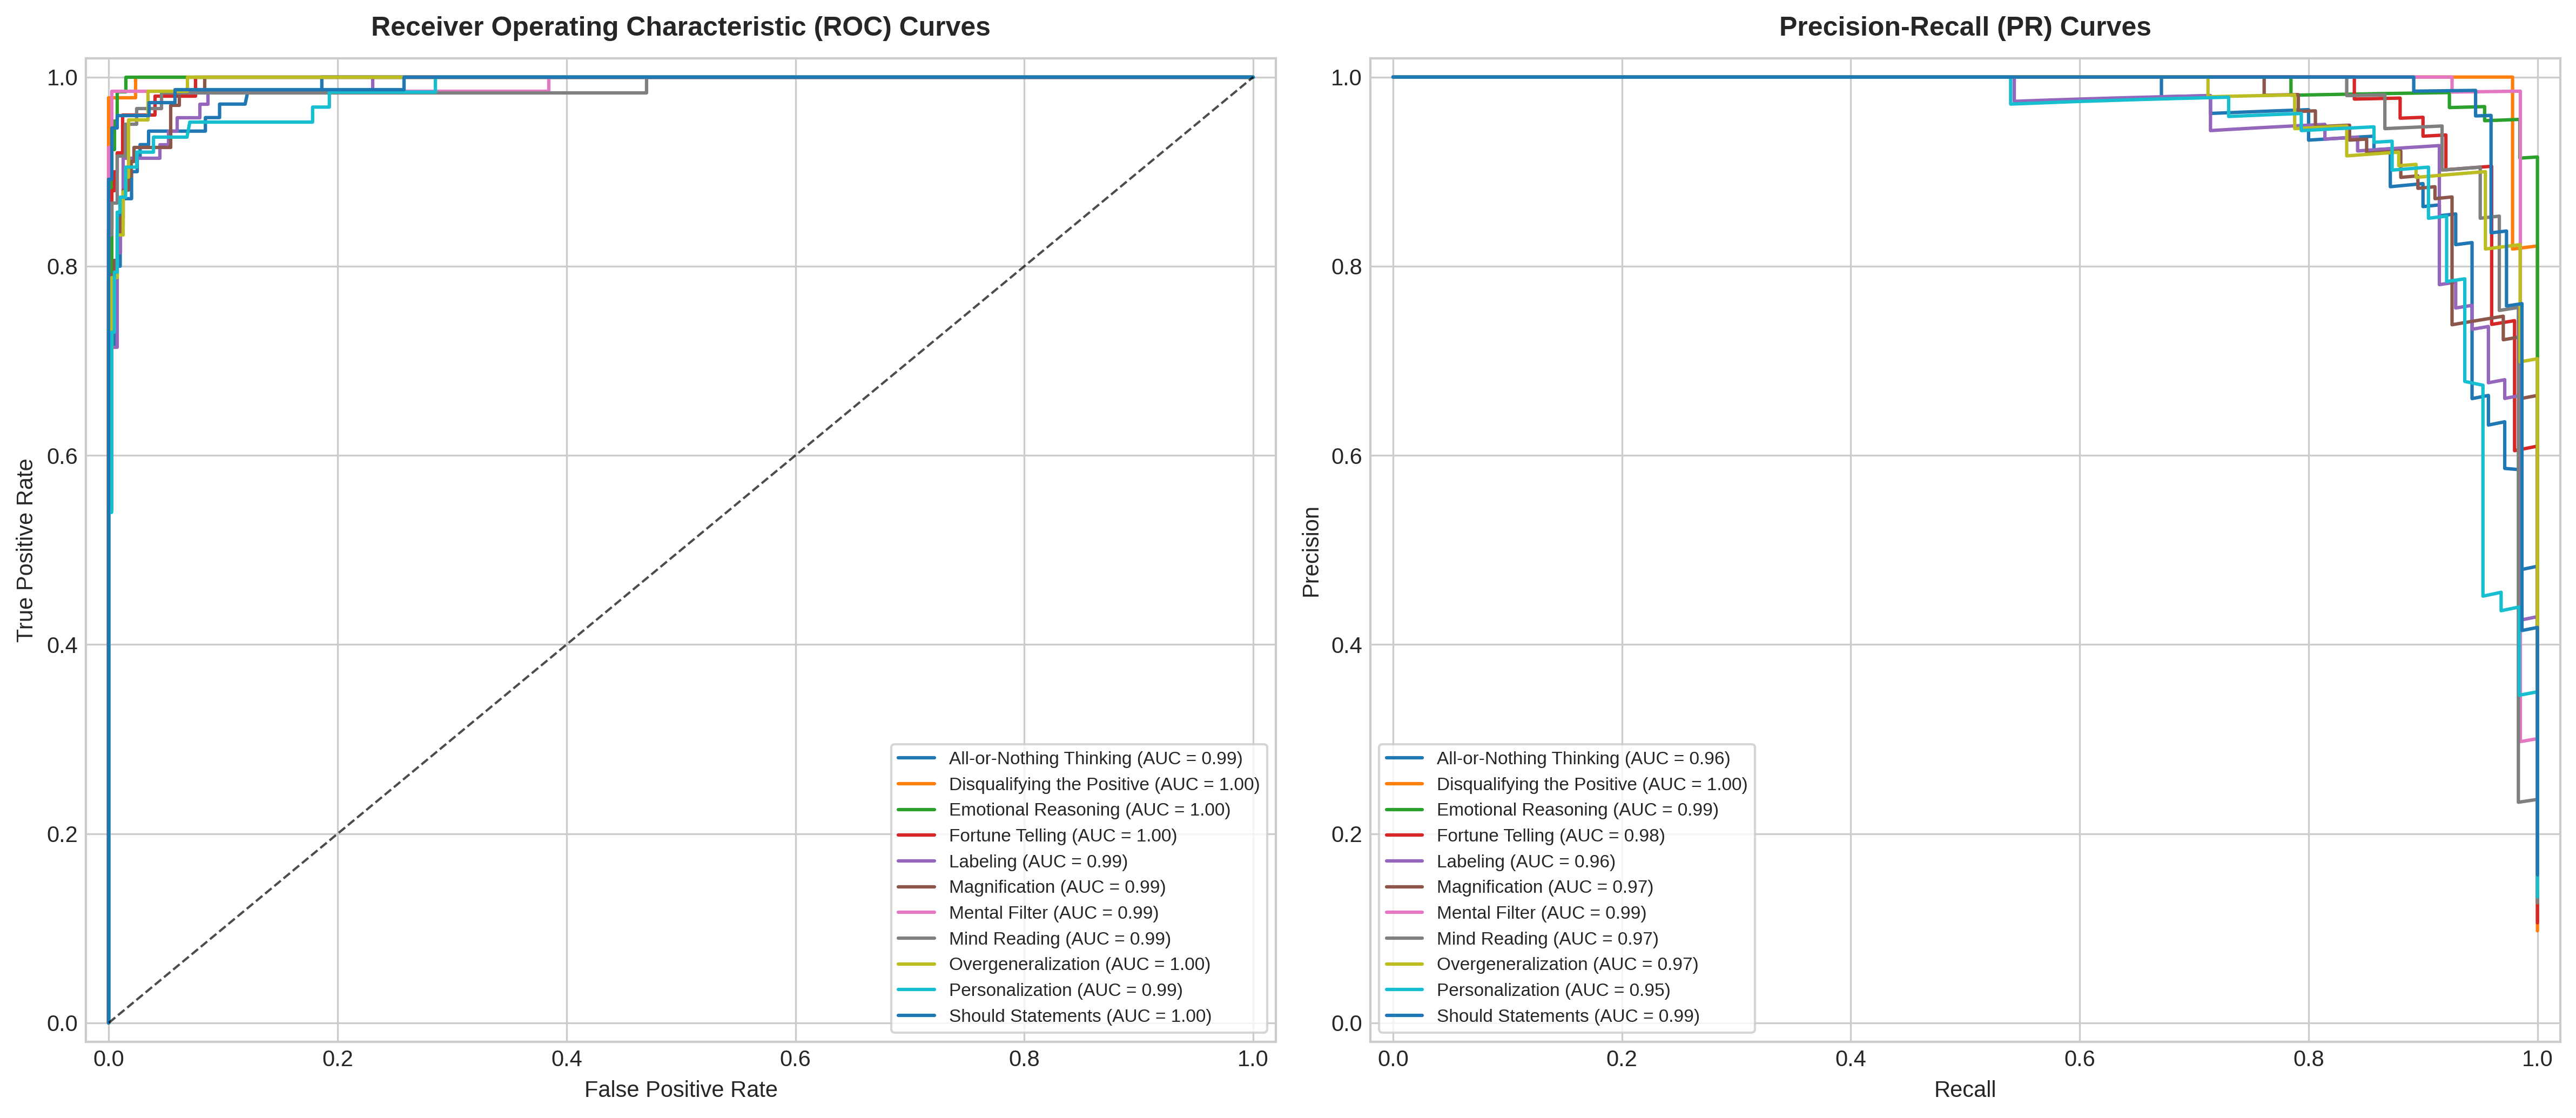


TUNED GLOBAL SYSTEM METRICS 
Macro F1:    9.3850e-01
Micro F1:    9.3746e-01
Weighted F1: 9.3734e-01


,Class Name,Optimal Threshold,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,TP,FP,FN,TN
0,All-or-Nothing Thinking,0.455,0.9242,0.8714,0.8971,0.9900,0.9580,61,5,9,398
1,Disqualifying the Positive,0.614,1.0000,0.9783,0.9890,0.9995,0.9961,45,0,1,427
2,Emotional Reasoning,0.347,0.9552,0.9846,0.9697,0.9991,0.9939,64,3,1,405
3,Fortune Telling,0.366,0.9057,0.9600,0.9320,0.9969,0.9801,48,5,2,418
4,Labeling,0.307,0.9275,0.9143,0.9209,0.9898,0.9557,64,5,6,398
5,Magnification,0.485,0.9219,0.8806,0.9008,0.9936,0.9681,59,5,8,401
6,Mental Filter,0.416,0.9851,0.9851,0.9851,0.9941,0.9886,66,1,1,405
7,Mind Reading,0.554,0.9483,0.9167,0.9322,0.9901,0.9742,55,3,5,410
8,Overgeneralization,0.436,0.9000,0.9545,0.9265,0.9956,0.9748,63,7,3,400
9,Personalization,0.495,0.9048,0.9048,0.9048,0.9856,0.9463,57,6,6,404


In [8]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    roc_curve, auc, precision_recall_curve, 
    f1_score, precision_score, recall_score, roc_auc_score
)

target_labels = sorted([
    'All-or-Nothing Thinking', 'Disqualifying the Positive', 'Emotional Reasoning',
    'Fortune Telling', 'Labeling', 'Magnification', 
    'Mental Filter', 'Mind Reading', 'Overgeneralization', 'Personalization', 
    'Should Statements'
])

print("Extracting validation predictions and logits...")
val_predictions = trainer.predict(val_ds)
logits = val_predictions.predictions
true_labels = val_predictions.label_ids

# Convert logits to stable probabilities via sigmoid
probs = 1 / (1 + np.exp(-logits))

# Storage for thresholds and metrics
best_thresholds = {}
per_class_metrics = []

# Setup crisp, academic-style figures (300 DPI ready)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7), dpi=300)

print("\n Finding optimized thresholds ")
for i, class_name in enumerate(target_labels):
    y_true = true_labels[:, i]
    y_prob = probs[:, i]
    
    # 1. Find the absolute best threshold for F1-Score
    thresholds = np.linspace(0.01, 0.99, 100)
    best_f1 = -1
    best_thresh = 0.5
    
    for t in thresholds:
        y_pred = (y_prob >= t).astype(int)
        score = f1_score(y_true, y_pred, zero_division=0)
        if score > best_f1:
            best_f1 = score
            best_thresh = t
            
    best_thresholds[class_name] = float(best_thresh)
    
    # 2. Calculate stable performance indices at the optimal cutoff
    final_preds = (y_prob >= best_thresh).astype(int)
    p_score = precision_score(y_true, final_preds, zero_division=0)
    r_score = recall_score(y_true, final_preds, zero_division=0)
    
    # Calculate Areas Under Curves
    try:
        class_roc_auc = roc_auc_score(y_true, y_prob)
    except ValueError:
        class_roc_auc = 0.5
        
    precision_vals, recall_vals, _ = precision_recall_curve(y_true, y_prob)
    class_pr_auc = auc(recall_vals, precision_vals)
    
    # Calculate simple Confusion Matrix elements for structural reporting
    tp = int(np.sum((final_preds == 1) & (y_true == 1)))
    fp = int(np.sum((final_preds == 1) & (y_true == 0)))
    fn = int(np.sum((final_preds == 0) & (y_true == 1)))
    tn = int(np.sum((final_preds == 0) & (y_true == 0)))
    
    per_class_metrics.append({
        "Class Name": class_name,
        "Optimal Threshold": round(best_thresh, 3),
        "Precision": round(p_score, 4),
        "Recall": round(r_score, 4),
        "F1-Score": round(best_f1, 4),
        "ROC-AUC": round(class_roc_auc, 4),
        "PR-AUC": round(class_pr_auc, 4),
        "TP": tp, "FP": fp, "FN": fn, "TN": tn
    })
    
    # 3. Plot ROC Curve
    fpr_vals, tpr_vals, _ = roc_curve(y_true, y_prob)
    ax1.plot(fpr_vals, tpr_vals, label=f'{class_name} (AUC = {class_roc_auc:.2f})', linewidth=1.5)
    
    # 4. Plot Precision-Recall Curve
    ax2.plot(recall_vals, precision_vals, label=f'{class_name} (AUC = {class_pr_auc:.2f})', linewidth=1.5)

# --- Format Plots for Paper Submission ---
ax1.plot([0, 1], [0, 1], 'k--', linewidth=1, alpha=0.7)
ax1.set_title('Receiver Operating Characteristic (ROC) Curves', fontsize=12, fontweight='bold', pad=10)
ax1.set_xlabel('False Positive Rate', fontsize=10)
ax1.set_ylabel('True Positive Rate', fontsize=10)
ax1.legend(loc='lower right', fontsize=8, frameon=True)
ax1.set_xlim([-0.02, 1.02])
ax1.set_ylim([-0.02, 1.02])

ax2.set_title('Precision-Recall (PR) Curves', fontsize=12, fontweight='bold', pad=10)
ax2.set_xlabel('Recall', fontsize=10)
ax2.set_ylabel('Precision', fontsize=10)
ax2.legend(loc='lower left', fontsize=8, frameon=True)
ax2.set_xlim([-0.02, 1.02])
ax2.set_ylim([-0.02, 1.02])

plt.tight_layout()
plt.savefig('curves.png', dpi=300, bbox_inches='tight')
plt.show()

# --- Compile Comprehensive Global Metrics ---
report_df = pd.DataFrame(per_class_metrics)

# Apply thresholds globally to evaluate system summaries
global_preds = np.zeros_like(probs, dtype=int)
for idx, class_name in enumerate(target_labels):
    global_preds[:, idx] = (probs[:, idx] >= best_thresholds[class_name]).astype(int)

macro_f1_tuned = f1_score(true_labels, global_preds, average='macro', zero_division=0)
micro_f1_tuned = f1_score(true_labels, global_preds, average='micro', zero_division=0)
weighted_f1_tuned = f1_score(true_labels, global_preds, average='weighted', zero_division=0)

print("\n" + "="*65)
print("TUNED GLOBAL SYSTEM METRICS ")
print("="*65)
print(f"Macro F1:    {macro_f1_tuned:.4e}")
print(f"Micro F1:    {micro_f1_tuned:.4e}")
print(f"Weighted F1: {weighted_f1_tuned:.4e}")
print("="*65)

# Output dataframe sorting classes by performance profile
report_df

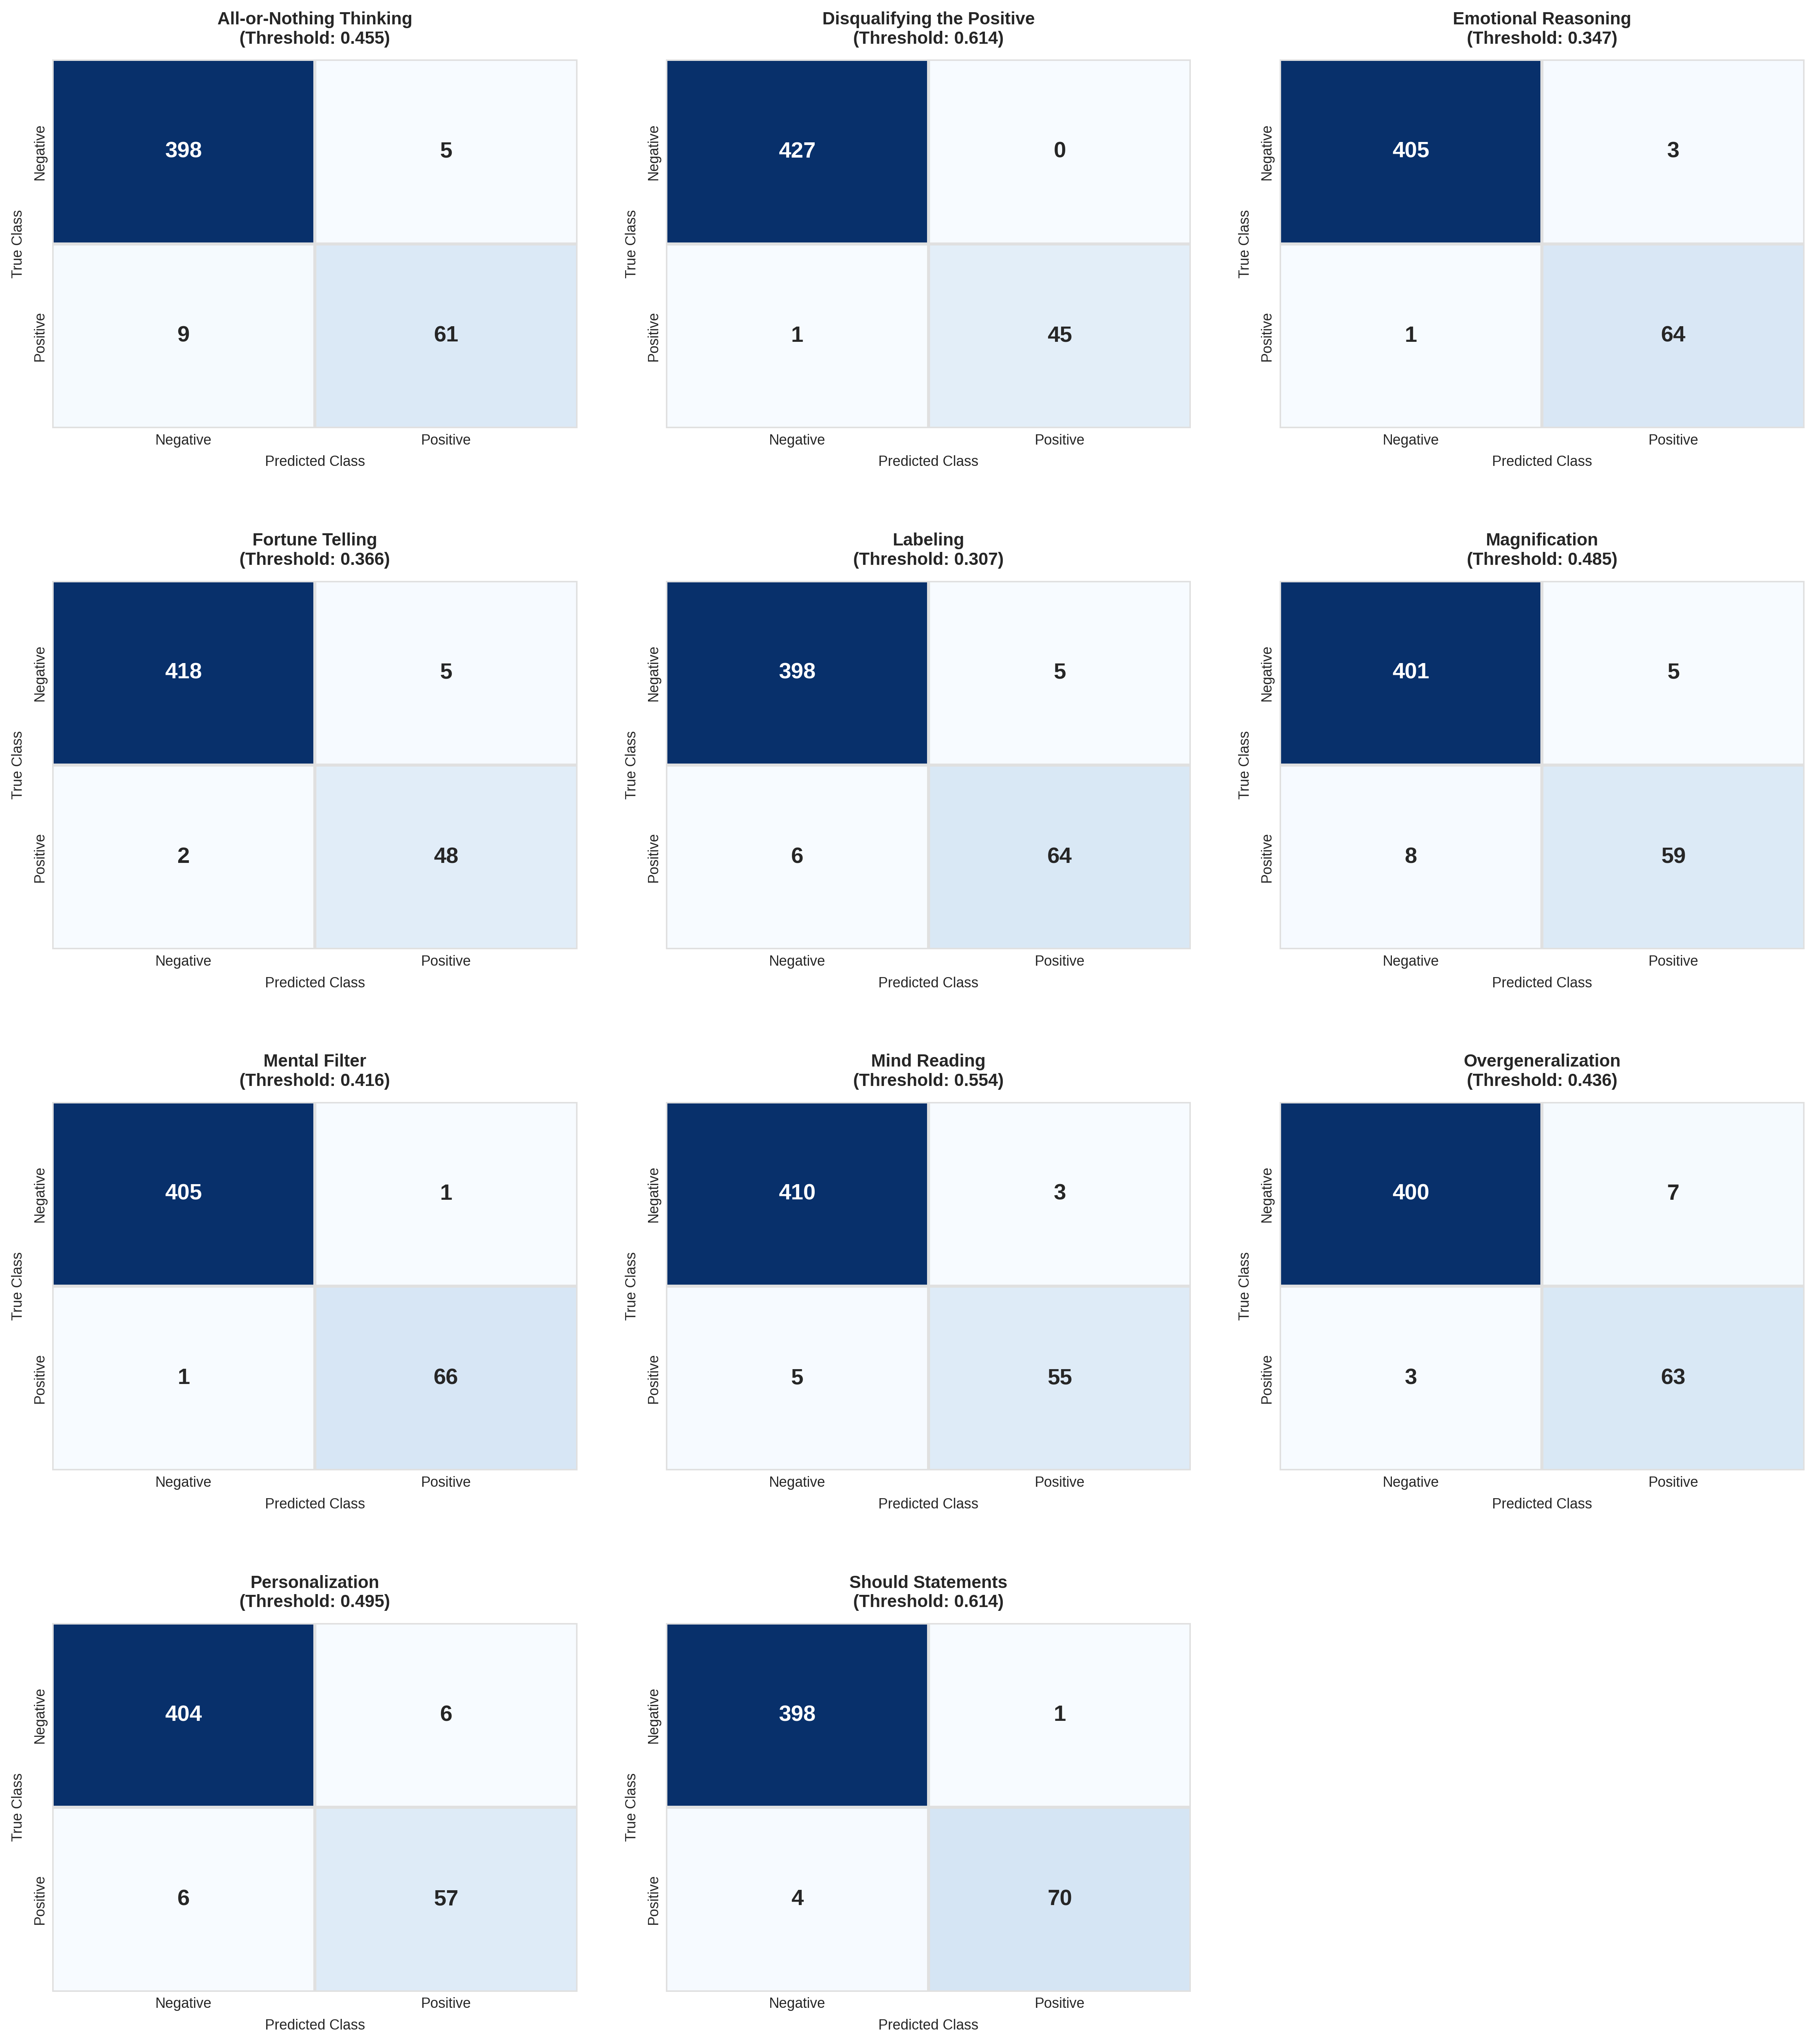

Multi-label matrix grid compiled and exported as 'confusion_matrices.png'!


In [9]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix



# Safety check: Fallback to 0.5 thresholds if the optimization cell wasn't run first
if 'best_thresholds' not in locals():
    print("'best_thresholds' not found in active memory. Defaulting all classes to 0.5 cutoff.")
    best_thresholds = {col: 0.5 for col in target_labels}

# Create a clean 4x3 grid layout (12 slots total for our 11 classes)
fig, axes = plt.subplots(4, 3, figsize=(16, 18), dpi=300)
axes = axes.ravel()  # Flatten the grid into an array for easy structural iteration


for i, class_name in enumerate(target_labels):
    y_true = true_labels[:, i]
    y_prob = probs[:, i]
    thresh = best_thresholds[class_name]
    
    # Binarize predictions based on that class's specific tuned threshold
    y_pred = (y_prob >= thresh).astype(int)
    
    # Compute the 2x2 matrix elements
    cm = confusion_matrix(y_true, y_pred)
    
    # Plotting using a clean, high-contrast academic Blue palette
    sns.heatmap(
        cm, 
        annot=True, 
        fmt='d', 
        ax=axes[i], 
        cmap='Blues', 
        cbar=False,
        annot_kws={'size': 14, 'weight': 'bold'},
        linewidths=1.5, 
        linecolor='#e0e0e0'
    )
    
    # Journal-grade axis text formatting
    axes[i].set_title(f"{class_name}\n(Threshold: {thresh:.3f})", fontsize=11, fontweight='bold', pad=10)
    axes[i].set_xlabel('Predicted Class', fontsize=9, labelpad=5)
    axes[i].set_ylabel('True Class', fontsize=9, labelpad=5)
    axes[i].set_xticklabels(['Negative', 'Positive'], fontsize=9)
    axes[i].set_yticklabels(['Negative', 'Positive'], fontsize=9, va='center')

# Remove the 12th empty layout slot to keep the figure symmetrical and clean
fig.delaxes(axes[11])

plt.tight_layout(h_pad=4.0, w_pad=3.0)

# Save image file directly to workspace for paper figures
plt.savefig('confusion_matrices.png', dpi=300, bbox_inches='tight')
plt.show()

print("Multi-label matrix grid compiled and exported as 'confusion_matrices.png'!")

In [10]:
import os
import json
import shutil

export_dir = "./stage1_cbt_export_package"
os.makedirs(export_dir, exist_ok=True)

print(" Saving fine-tuned ModernBERT model core and weights...")
# This automatically packages model config, tokens, and safety layers
trainer.save_model(os.path.join(export_dir, "best_cbt_model"))
tokenizer.save_pretrained(os.path.join(export_dir, "best_cbt_model"))

print(" Exporting optimized tuning threshold dictionary...")
threshold_payload = {
    "model_name": "ModernBERT-large-CBT-Stage1",
    "num_classes": len(best_thresholds),
    "thresholds": best_thresholds
}
with open(os.path.join(export_dir, "optimal_thresholds.json"), "w") as f:
    json.dump(threshold_payload, f, indent=4)

print(" Saving data-frames and high-res curves...")
# Export evaluation stats and graphics directly into the package structure
report_df.to_csv(os.path.join(export_dir, "evaluation_metrics_report.csv"), index=False)
if os.path.exists("publication_curves.png"):
    shutil.copy("publication_curves.png", os.path.join(export_dir, "publication_curves.png"))

# Create a system configuration summary to make Stage 2 loading easier
summary_notes = f"""
============================================================
STAGE 1 TRAINING SUMMARY NOTES
============================================================
Base Model: answerdotai/ModernBERT-large
Task Type: Multi-label Cognitive Distortion Classification (11 Classes)
Tuned Macro F1: {macro_f1_tuned:.4f}
Tuned Micro F1: {micro_f1_tuned:.4f}
Tuned Weighted F1: {weighted_f1_tuned:.4f}
============================================================
"""
with open(os.path.join(export_dir, "training_summary.txt"), "w") as f:
    f.write(summary_notes.strip())

print(" Compressing entire bundle for easy download...")
archive_output = "/kaggle/working/stage1_cbt_complete_export"
shutil.make_archive(archive_output, 'zip', export_dir)

print("\n" + "="*60)
print(" EXPORT COMPLETE & VERIFIED!")
print(f"Your download file is ready at: {archive_output}.zip")
print("This contains your optimized thresholds, graphs, and model.")
print("="*60)

 Saving fine-tuned ModernBERT model core and weights...


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

 Exporting optimized tuning threshold dictionary...
 Saving data-frames and high-res curves...
 Compressing entire bundle for easy download...

 EXPORT COMPLETE & VERIFIED!
Your download file is ready at: /kaggle/working/stage1_cbt_complete_export.zip
This contains your optimized thresholds, graphs, and model.


taking to gdrive

In [11]:
# =========================================================
# GOOGLE DRIVE DIRECT UPLOAD (LARGE FILE SAFE)
# =========================================================

!pip install -q --upgrade google-api-python-client google-auth-httplib2 google-auth-oauthlib

# =========================================================
# AUTHENTICATE
# =========================================================

from huggingface_hub import login
from google.colab import auth
import google.auth
from googleapiclient.discovery import build
from googleapiclient.http import MediaFileUpload

auth.authenticate_user()

creds, _ = google.auth.default()

service = build(
    "drive",
    "v3",
    credentials=creds
)

print("GOOGLE DRIVE AUTH SUCCESS")

# =========================================================
# FILE PATH
# =========================================================

FILE_PATH = "/kaggle/working/stage1_cbt_complete_export.zip"

# =========================================================
# UPLOAD
# =========================================================

file_metadata = {
    "name": "stage1_cbt_complete_export.zip"
}

media = MediaFileUpload(
    FILE_PATH,
    resumable=True
)

uploaded_file = service.files().create(
    body=file_metadata,
    media_body=media,
    fields="id"
).execute()

print("\nUPLOAD COMPLETE")
print("FILE ID:", uploaded_file.get("id"))

print(
    "\nOPEN FILE:\n",
    f"https://drive.google.com/file/d/{uploaded_file.get('id')}/view"
)

GOOGLE DRIVE AUTH SUCCESS

UPLOAD COMPLETE
FILE ID: 1mpT_p8MLA1H2UfZvWYT2BPE_DqNU4sTx

OPEN FILE:
 https://drive.google.com/file/d/1mpT_p8MLA1H2UfZvWYT2BPE_DqNU4sTx/view


doing ground baeline for th e mental roberta here 

In [7]:
%%writefile mentalroberta_multilabel_baseline.py

import os, random, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from datasets import Dataset
from sklearn.metrics import f1_score
from transformers import (
    AutoTokenizer,
    AutoModel,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)

# =====================================================================================
# CONFIG
# =====================================================================================

SEED = 2025
MODEL_NAME = "AIMH/mental-roberta-large"   # Mental RoBERTa checkpoint
MAX_LEN = 512
NUM_LABELS = 10   # 10 distortion categories (exclude "No Distortion")
BATCH_SIZE = 2
EPOCHS = 8
LR = 2e-5

DISTORTION_LABELS = [
    "Overgeneralization",
    "Mind Reading",
    "Magnification",
    "Labeling",
    "Personalization",
    "Fortune-telling",
    "Emotional Reasoning",
    "Mental filter",
    "Should statements",
    "All-or-nothing thinking"
]

SAVE_DIR = "./mentalroberta_multilabel_baseline"
os.makedirs(SAVE_DIR, exist_ok=True)

# =====================================================================================
# SEED
# =====================================================================================

random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

# =====================================================================================
# DATA
# =====================================================================================

df = pd.read_csv("/kaggle/input/datasets/sagarikashreevastava/cognitive-distortion-detetction-dataset/Annotated_data.csv")

df["Patient Question"] = df["Patient Question"].fillna("").astype(str).str.strip()
df["Dominant Distortion"] = df["Dominant Distortion"].fillna("").astype(str).str.strip()
df["Secondary Distortion (Optional)"] = df["Secondary Distortion (Optional)"].fillna("").astype(str).str.strip()

# Build multi-hot label matrix
multi_labels = np.zeros((len(df), NUM_LABELS), dtype=np.float32)

for i, row in df.iterrows():
    dom = row["Dominant Distortion"]
    sec = row["Secondary Distortion (Optional)"]

    if dom in DISTORTION_LABELS:
        multi_labels[i, DISTORTION_LABELS.index(dom)] = 1.0
    if sec in DISTORTION_LABELS:
        multi_labels[i, DISTORTION_LABELS.index(sec)] = 1.0
    # If "No Distortion", leave vector all zeros

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

dataset = Dataset.from_dict({
    "text": df["Patient Question"].tolist(),
    "labels": multi_labels.tolist()
})

def tokenize_function(example):
    enc = tokenizer(example["text"], truncation=True, max_length=MAX_LEN, padding=False)
    return {"input_ids": enc["input_ids"], "attention_mask": enc["attention_mask"], "labels": example["labels"]}

dataset = dataset.map(tokenize_function)

train_testvalid = dataset.train_test_split(test_size=0.20, seed=SEED)
test_valid = train_testvalid["test"].train_test_split(test_size=0.50, seed=SEED)

train_dataset = train_testvalid["train"]
val_dataset = test_valid["train"]
test_dataset = test_valid["test"]

print(f"[INFO] Dataset split sizes -> Train: {len(train_dataset)} | Val: {len(val_dataset)} | Test: {len(test_dataset)}")

# =====================================================================================
# BASELINE MODEL
# =====================================================================================

class MentalRoBERTaBaseline(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(MODEL_NAME)
        hidden = self.encoder.config.hidden_size
        self.dropout = nn.Dropout(0.2)
        self.classifier = nn.Linear(hidden, NUM_LABELS)
        self.loss_fn = nn.BCEWithLogitsLoss()

    def forward(self, input_ids, attention_mask, labels=None):
        outputs = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
        cls_repr = outputs.last_hidden_state[:, 0]  # CLS token
        cls_repr = self.dropout(cls_repr)
        logits = self.classifier(cls_repr)
        loss = None
        if labels is not None:
            loss = self.loss_fn(logits, labels)
        return {"loss": loss, "logits": logits}

# =====================================================================================
# METRICS
# =====================================================================================

def compute_metrics(eval_preds):
    logits, labels = eval_preds
    probs = torch.sigmoid(torch.tensor(logits)).numpy()
    preds = (probs >= 0.5).astype(int)
    return {
        "macro_f1": f1_score(labels, preds, average="macro", zero_division=0),
        "micro_f1": f1_score(labels, preds, average="micro", zero_division=0)
    }

# =====================================================================================
# TRAINER
# =====================================================================================

model = MentalRoBERTaBaseline()
training_args = TrainingArguments(
    output_dir="./mentalroberta_multilabel_out",
    learning_rate=LR,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    gradient_accumulation_steps=2,
    num_train_epochs=EPOCHS,
    bf16=True,
    eval_strategy="epoch",
    save_strategy="no",
    logging_steps=25,
    report_to="none",
    ddp_find_unused_parameters=True
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics,
)

trainer.train()

# =====================================================================================
# THRESHOLD CALIBRATION + TEST EVAL
# =====================================================================================

print("\n" + "="*60)
print("[STAGE 1] CALIBRATING THRESHOLDS ON VALIDATION SET")
print("="*60)

val_out = trainer.predict(val_dataset)
val_logits = val_out.predictions
val_labels = val_out.label_ids
val_probs = torch.sigmoid(torch.tensor(val_logits)).numpy()

calibrated_thresholds = []
for i in range(NUM_LABELS):
    best_thr, best_f1 = 0.5, -1.0
    for thr in np.arange(0.05, 0.95, 0.01):
        preds = (val_probs[:, i] >= thr).astype(int)
        f1 = f1_score(val_labels[:, i], preds, zero_division=0)
        if f1 > best_f1:
            best_f1, best_thr = f1, thr
    calibrated_thresholds.append(best_thr)

calibrated_thresholds = np.array(calibrated_thresholds)
np.save(os.path.join(SAVE_DIR, "calibrated_thresholds.npy"), calibrated_thresholds)
print(f"[CALIBRATED THRESHOLDS] -> {calibrated_thresholds.tolist()}")

print("\n" + "="*60)
print("[STAGE 2] FINAL TEST SET EVALUATION")
print("="*60)

test_out = trainer.predict(test_dataset)
test_logits = test_out.predictions
test_labels = test_out.label_ids
test_probs = torch.sigmoid(torch.tensor(test_logits)).numpy()

test_preds = (test_probs >= calibrated_thresholds).astype(int)

test_macro = f1_score(test_labels, test_preds, average="macro", zero_division=0)
test_micro = f1_score(test_labels, test_preds, average="micro", zero_division=0)

print("[METRICS] MentalRoBERTa Multi-Label Baseline Performance (Calibrated):")
print(f"TEST MACRO F1 : {test_macro:.4f}")
print(f"TEST MICRO F1 : {test_micro:.4f}")
print("="*60)


Overwriting mentalroberta_multilabel_baseline.py


In [8]:
!torchrun --nproc_per_node=2 mentalroberta_multilabel_baseline.py


W0704 18:48:14.510000 775 torch/distributed/run.py:852] 
W0704 18:48:14.510000 775 torch/distributed/run.py:852] *****************************************
W0704 18:48:14.510000 775 torch/distributed/run.py:852] Setting OMP_NUM_THREADS environment variable for each process to be 1 in default, to avoid your system being overloaded, please further tune the variable for optimal performance in your application as needed. 
W0704 18:48:14.510000 775 torch/distributed/run.py:852] *****************************************
Map: 100%|█████████████████████████| 2530/2530 [00:01<00:00, 1357.45 examples/s]
[INFO] Dataset split sizes -> Train: 2024 | Val: 253 | Test: 253
Map: 100%|█████████████████████████| 2530/2530 [00:01<00:00, 1354.67 examples/s]
[INFO] Dataset split sizes -> Train: 2024 | Val: 253 | Test: 253
Loading weights: 100%|█| 389/389 [00:00<00:00, 2340.28it/s, Materializing param=
RobertaModel LOAD REPORT from: AIMH/mental-roberta-large
Key                             | Status     | 
---